<a href="https://colab.research.google.com/github/rudrakshagrawal60-netizen/arc_prize_2026_solution/blob/main/arc_prize_2026_solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import json
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ARC dataset ke official GitHub repository se training tasks download karne ke liye
import os
import urllib.request

os.makedirs('arc_data', exist_ok=True)

# Example training JSON URL (ARC-AGI dataset)
train_url = "https://raw.githubusercontent.com/fchollet/ARC-AGI/master/data/training/00d62c1b.json"
file_path = "arc_data/sample_task.json"

if not os.path.exists(file_path):
    urllib.request.urlretrieve(train_url, file_path)
    print("Sample ARC task downloaded!")
else:
    print("Task already exists locally.")

Sample ARC task downloaded!


Task already exists locally.


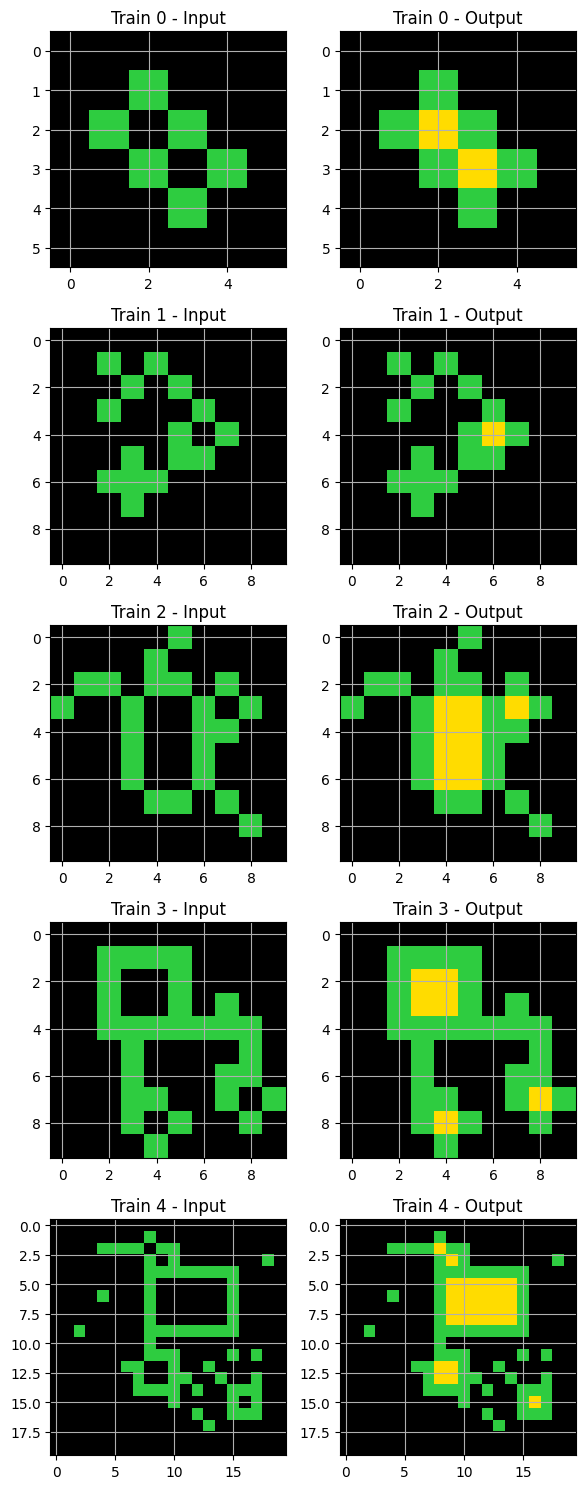

In [6]:
import json
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

# 1. Dataset download code
os.makedirs('arc_data', exist_ok=True)
train_url = "https://raw.githubusercontent.com/fchollet/ARC-AGI/master/data/training/00d62c1b.json"
file_path = "arc_data/sample_task.json"

if not os.path.exists(file_path):
    urllib.request.urlretrieve(train_url, file_path)
    print("Sample ARC task downloaded!")
else:
    print("Task already exists locally.")

# 2. Corrected Plotting Function
def plot_task(task):
    cmap = colors.ListedColormap([
        '#000000', '#0074D9', '#FF4136', '#2ECC40', '#FFDC00',
        '#AAAAAA', '#F012BE', '#FF851B', '#7FDBFF', '#B10DC9'
    ])
    norm = colors.Normalize(vmin=0, vmax=9)

    num_train = len(task['train'])
    fig, axs = plt.subplots(num_train, 2, figsize=(6, 3 * num_train))

    # Handle single row case where axs might be a 1D array
    if num_train == 1:
        axs = np.array([axs])

    for i, ex in enumerate(task['train']):
        # Input grid
        axs[i, 0].imshow(np.array(ex['input']), cmap=cmap, norm=norm)
        axs[i, 0].set_title(f'Train {i} - Input')
        axs[i, 0].grid(True) # Corrected from axis('grid')

        # Output grid
        axs[i, 1].imshow(np.array(ex['output']), cmap=cmap, norm=norm)
        axs[i, 1].set_title(f'Train {i} - Output')
        axs[i, 1].grid(True) # Corrected from axis('grid')

    plt.tight_layout()
    plt.show()

# 3. Load and visualize
with open('arc_data/sample_task.json', 'r') as f:
    task_data = json.load(f)

plot_task(task_data)

In [4]:
def extract_objects(grid):
    """Grid ke andar connected non-zero pixels (objects) ko find karta hai."""
    grid_arr = np.array(grid)
    unique_colors = np.unique(grid_arr)
    objects = []

    for color in unique_colors:
        if color == 0: continue # Background ignore karein
        coords = np.argwhere(grid_arr == color)
        objects.append({
            'color': int(color),
            'min_row': coords[:, 0].min(),
            'max_row': coords[:, 0].max(),
            'min_col': coords[:, 1].min(),
            'max_col': coords[:, 1].max(),
            'size': len(coords)
        })
    return objects

# Test the function on the first training input
sample_input = task_data['train'][0]['input']
detected_objects = extract_objects(sample_input)
print("Detected Objects in Training Example 0:", detected_objects)

Detected Objects in Training Example 0: [{'color': 3, 'min_row': np.int64(1), 'max_row': np.int64(4), 'min_col': np.int64(1), 'max_col': np.int64(4), 'size': 6}]


In [7]:
import numpy as np

def solve_arc_grid(input_grid):
    """
    Yahan aapko apna custom logic likhna hai jo input_grid (2D list/numpy array)
    ko analyze karke predicted output grid return kare.
    """
    grid = np.array(input_grid)

    # EXAMPLE LOGIC: Agar task color replacement ka hai
    # Jaise ki grid me agar color 1 hai toh use color 2 kar do:
    # grid[grid == 1] = 2

    # Abhi ke liye ye same input ko output return kar raha hai (baseline)
    predicted_output = grid.tolist()

    return predicted_output

# Test your solver on a training input
sample_input = task_data['train'][0]['input']
prediction = solve_arc_grid(sample_input)
print("Predicted Output:", prediction)

Predicted Output: [[0, 0, 0, 0, 0, 0], [0, 0, 3, 0, 0, 0], [0, 3, 0, 3, 0, 0], [0, 0, 3, 0, 3, 0], [0, 0, 0, 3, 0, 0], [0, 0, 0, 0, 0, 0]]
